# Hipótese 3: Movimentação de Passageiros e Volume de Alarmes por Estação

## 1. Contexto
As portas de plataforma são equipamentos onde acontece ciclos de abertura e fechamento. A hipótese testa se estações com maior movimentação de passageiros apresentam mais alarmes.

## 2. Questão investigada
Se a movimentação de passageiros é maior, a taxa de alarmes deveria ser maior na devida estação.

## 3. Metodologia
A análise compara a taxa de alarmes de obstrução por porta e por dia ativo entre estações, usando o alarme OBS como o tipo comparável entre os dados disponíveis. Antes da comparação, a seção 4 verifica se os dados são de fato comparáveis, vendo a uniformidade da instrumentação, base de ativos, cobertura temporal e consistência do tempo de normalização. Essa verificação define também o recorte do teste: eventos normalizados em até 30 segundos são descartados por não constituírem fazerem parte de uma falha acionável.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from pathlib import Path
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 120

AZUL, AQUA, CINZA = '#2a78d6', '#1baf7a', '#9a9a94'

# Resolução do diretório de dados (cópia local do repositório ou pacote original)
CANDIDATOS = [Path("../../data/Informações de Manutenção - Motiva"),
              Path.home() / "Downloads" / "Informações de Manutenção - Motiva"]
DATA_DIR = next((p for p in CANDIDATOS if p.exists()), None)
if DATA_DIR is None:
    raise FileNotFoundError("Diretório de dados não encontrado. Ajuste a lista CANDIDATOS.")

df_alarmes = pd.read_excel(DATA_DIR / "Alarmes do sistema de PSD.xlsx")
df_tags    = pd.read_excel(DATA_DIR / "Estrutura das TAG_s dos alarmes da PSD.xlsx")

N_BRUTO = len(df_alarmes)
df_alarmes = df_alarmes.dropna(subset=['Estação']).copy()   # 3 registros sem estação identificada

df_alarmes['DT_Alarme'] = pd.to_datetime(df_alarmes['Horário do Alarme'], errors='coerce')
df_alarmes['DT_Normal'] = pd.to_datetime(df_alarmes['Horário da Normalizacao'], errors='coerce')
# A via (plataforma) só existe dentro da TAG; a nomenclatura convive em dois padrões
# ('PSD_BUT_BUT2_PDM09_OBS' e 'PSD_P_BUT1_PDM10_OA'), com o bloco '<EST><via>_' em comum.
df_alarmes['Via'] = df_alarmes['TAG'].str.extract(r'_[A-Z]{3}(\d)_(?:PDM|PSE|PFP|MDU)')

print(f"Total de alarmes ..... {len(df_alarmes):>7,} registros x {df_alarmes.shape[1]} colunas "
      f"({N_BRUTO - len(df_alarmes)} descartados por não identificarem a estação)")
print(f"Estações cobertas .... {df_alarmes['Estação'].nunique()} ({', '.join(sorted(df_alarmes['Estação'].unique()))})")
print(f"Período dos dados .... {df_alarmes['DT_Alarme'].min():%d/%m/%Y} a {df_alarmes['DT_Alarme'].max():%d/%m/%Y}")

Total de alarmes ..... 150,000 registros x 10 colunas (3 descartados por não identificarem a estação)
Estações cobertas .... 6 (BUT, FAL, FRA, FRE, HIG, LUZ)
Período dos dados .... 27/02/2023 a 12/05/2026


---

## 4. Caracterização do conjunto de dados
Antes de comparar estações, é importante ver se os dados são realmente comparáveis. O dicionário em baixo mostra os campos usados na análise.


In [2]:
dic_alarmes = pd.DataFrame([
    ("TAG",                     "Texto",      "Identificador hierárquico do ponto monitorado: sistema, estação, via, componente e tipo de erro."),
    ("Horário do Alarme",       "Datetime",   "Carimbo de tempo do disparo do alarme, com resolução de milissegundos."),
    ("Estação",                 "Categórica", "Sigla de três letras da estação onde o alarme ocorreu."),
    ("Porta",                   "Inteiro",    "Número da folha de porta (PDM) na plataforma, de 1 a 24."),
    ("Alarme",                  "Categórica", "Código do tipo de anomalia detectada."),
    ("Horário da Normalizacao", "Datetime",   "Carimbo de tempo do retorno do ponto à condição normal."),
    ("Tempo de Normalização",   "Texto",      "Duração da anomalia em formato textual ('0 dias, 00:00:01')."),
], columns=["Campo", "Tipo", "Descrição"])

pd.set_option('display.max_colwidth', 100)
print(dic_alarmes.to_string(index=False))

print("\n--- Decomposição da TAG ---")
print("Exemplo: PSD_FAL_FAL2_PDM09_OBS")
print("  PSD    -> sistema (Platform Screen Doors)")
print("  FAL    -> estação (Faria Lima)")
print("  FAL2   -> via / plataforma (sentido 2)")
print("  PDM09  -> folha de porta nº 9")
print("  OBS    -> tipo de alarme (obstrução)")

                  Campo       Tipo                                                                                        Descrição
                    TAG      Texto Identificador hierárquico do ponto monitorado: sistema, estação, via, componente e tipo de erro.
      Horário do Alarme   Datetime                           Carimbo de tempo do disparo do alarme, com resolução de milissegundos.
                Estação Categórica                                           Sigla de três letras da estação onde o alarme ocorreu.
                  Porta    Inteiro                                         Número da folha de porta (PDM) na plataforma, de 1 a 24.
                 Alarme Categórica                                                            Código do tipo de anomalia detectada.
Horário da Normalizacao   Datetime                                          Carimbo de tempo do retorno do ponto à condição normal.
  Tempo de Normalização      Texto                                     Duraç

A TAG é um campo composto: sozinha ela carrega estação, via, porta e tipo de alarme. A via (plataforma 1 ou 2) só existe dentro dela, sem coluna própria, é um recurso disponível, porém não explicitado.

### 4.2 Achado nº 1 — falta de marca de tempo
Um achado importante foi que uma grande parte dos registros não possui horário de alarme, apesar de o horário de normalização estar completo. Isso acaba comprometendo a comparação direta entre estações, porque a perda não é igual.

In [3]:
qualidade = pd.DataFrame({
    'Nulos': df_alarmes.isna().sum(),
    '% Nulos': (df_alarmes.isna().mean() * 100).round(1),
    'Distintos': df_alarmes.nunique(),
})
print(qualidade.to_string())

perda = df_alarmes.assign(sem_dt=df_alarmes['DT_Alarme'].isna()).groupby('Estação').agg(
    registros=('sem_dt', 'size'),
    sem_horario=('sem_dt', 'sum'),
)
perda['% perdido'] = (perda['sem_horario'] / perda['registros'] * 100).round(1)

print("\nPerda de carimbo de tempo por estação:")
print(perda.sort_values('% perdido', ascending=False).to_string())
print(f"\nTotal sem carimbo de tempo: {df_alarmes['DT_Alarme'].isna().sum():,} "
      f"({df_alarmes['DT_Alarme'].isna().mean()*100:.1f}% da base)")

                         Nulos  % Nulos  Distintos
TAG                          0      0.0        377
Horário do Alarme        37249     24.8      36477
Estação                      0      0.0          6
Porta                        0      0.0         24
Alarme                       0      0.0          8
Horário da Normalizacao      0      0.0      35360
Tempo de Normalização        0      0.0      56673
DT_Alarme                37249     24.8      36477
DT_Normal                    0      0.0      35360
Via                          0      0.0          2

Perda de carimbo de tempo por estação:
         registros  sem_horario  % perdido
Estação                                   
FRE           8399         7564       90.1
FAL          17079        11046       64.7
HIG          24385         5207       21.4
BUT          57214        11629       20.3
LUZ          14517          810        5.6
FRA          28406          993        3.5

Total sem carimbo de tempo: 37,249 (24.8% da base)


A perda é de ~25% da base e fortemente desigual: Oscar Freire perde 90% dos registros e Faria Lima 65%, enquanto Fradique Coutinho e Luz perdem menos de 6%. Comparar volumes brutos sob esse regime produziria um ranking que mede qualidade de exportação, não movimentação.

### 4.3 Achado nº 2 — instrumentação diferente entre estações
No segundo achado, foi analisado o cruzamento entre estação e tipo de alarme, para ver o que pode ou não ser comparado.

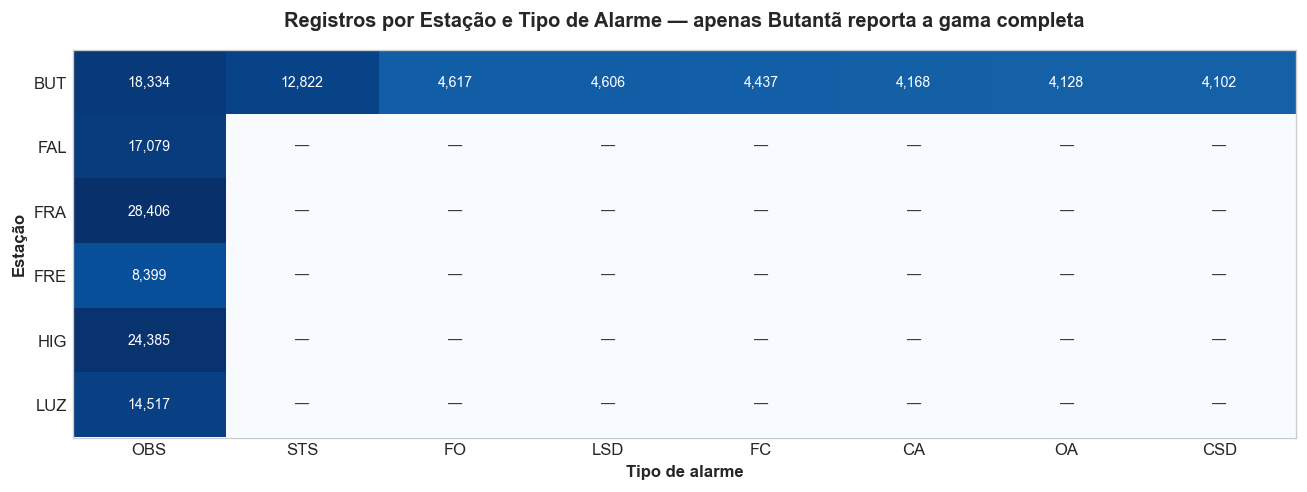

        Ocorrências                   Descrição documentada
Alarme                                                     
OBS          111120                 *** NÃO DOCUMENTADO ***
STS           12822                      Status de nb n MDU
FO             4617    Esforço de Abertura Excedeu o Limite
LSD            4606                 *** NÃO DOCUMENTADO ***
FC             4437  Esforço de Fechamento Excedeu o Limite
CA             4168          Excedido o Tempo de Fechamento
OA             4128            Excedido o Tempo de Abertura
CSD            4102                 *** NÃO DOCUMENTADO ***


In [4]:
tabela = pd.crosstab(df_alarmes['Estação'], df_alarmes['Alarme'])
tabela = tabela[tabela.sum().sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 4.2))
ax.imshow(np.log10(tabela.values + 1), cmap='Blues', aspect='auto')
ax.set_xticks(range(len(tabela.columns)), tabela.columns)
ax.set_yticks(range(len(tabela.index)), tabela.index)

for i in range(tabela.shape[0]):
    for j in range(tabela.shape[1]):
        v = tabela.values[i, j]
        ax.text(j, i, f'{v:,}' if v else '—', ha='center', va='center', fontsize=8.5,
                color='white' if np.log10(v + 1) > 3.5 else '#333333')

ax.set_title('Registros por Estação e Tipo de Alarme — apenas Butantã reporta a gama completa',
             fontsize=12, fontweight='bold', pad=14)
ax.set_xlabel('Tipo de alarme', fontsize=10, fontweight='bold')
ax.set_ylabel('Estação', fontsize=10, fontweight='bold')
ax.grid(False)
plt.tight_layout()
plt.show()

doc = df_tags.dropna(subset=['Erro']).drop_duplicates('Erro').set_index('Erro')['Informação']
ALIAS = {'OA': 'AO'}   # o documento de estrutura registra como 'AO' o código gravado como 'OA'
tipos = pd.DataFrame({
    'Ocorrências': df_alarmes['Alarme'].value_counts(),
    'Descrição documentada': [doc.get(ALIAS.get(c, c), '*** NÃO DOCUMENTADO ***')
                              for c in df_alarmes['Alarme'].value_counts().index],
})
tipos['Descrição documentada'] = (tipos['Descrição documentada']
                                  .str.replace(r'\s*de nb n PDM \(n=1 até 24\)', '', regex=True)
                                  .str.replace(r'\s*\(n=1 até 24\)', '', regex=True))
print(tipos.to_string())

### 4.4 Composição do alarme OBS
Antes de comparar volumes de OBS entre estações, é preciso saber do que esse alarme é composto, nem toda obstrução detectada configura falha de manutenção. Além disso, o tipo de alarme OBS foi utilizado para comparação, já que os outros tipos de alarme não aparacem nas estações exceto no butantã.


In [5]:
obs = df_alarmes[(df_alarmes['Alarme'] == 'OBS') & df_alarmes['DT_Alarme'].notna()].copy()
obs['Data'] = obs['DT_Alarme'].dt.date
obs['dur_s'] = (obs['DT_Normal'] - obs['DT_Alarme']).dt.total_seconds()
obs['acionavel'] = obs['dur_s'] > 30

resumo = obs.groupby('Estação').agg(
    total=('dur_s', 'size'),
    acionaveis=('acionavel', 'sum'),
)
resumo['curtos'] = resumo['total'] - resumo['acionaveis']
resumo['% acionaveis'] = (resumo['acionaveis'] / resumo['total'] * 100).round(1)
print(resumo.to_string())

         total  acionaveis  curtos  % acionaveis
Estação                                         
BUT      15316       13467    1849          87.9
FAL       6033        3962    2071          65.7
FRA      27413       25582    1831          93.3
FRE        835         280     555          33.5
HIG      19178        7650   11528          39.9
LUZ      13707        3520   10187          25.7


In [6]:
print("Distribuição do tempo entre alarme e normalização (segundos):")
print(obs['dur_s'].describe(percentiles=[.05, .25, .5, .75, .95]).round(1).to_string())

print("\nDistribuição por faixa de duração:")
FAIXAS = [-1, 1, 5, 30, 3600, 86400, 7*86400, np.inf]
ROT_FAIXAS = ['até 1 s', '1-5 s', '5-30 s', '30 s - 1 h', '1 h - 1 dia', '1-7 dias', 'mais de 7 dias']
faixa = pd.cut(obs['dur_s'], FAIXAS, labels=ROT_FAIXAS)
print((faixa.value_counts().sort_index() / len(obs) * 100).round(1).to_string())

CURTO, LONGO = obs['dur_s'] <= 30, obs['dur_s'] > 86400
diag = pd.DataFrame({
    'registros': obs.groupby('Estação')['dur_s'].size(),
    '% curtos (<=30s)': (obs.assign(f=CURTO).groupby('Estação')['f'].mean() * 100).round(1),
    '% longos (>1 dia)': (obs.assign(f=LONGO).groupby('Estação')['f'].mean() * 100).round(1),
})
print("\nComposição da base por estação:")
print(diag.to_string())

Distribuição do tempo entre alarme e normalização (segundos):
count       82482.0
mean      1334988.6
std       2258300.4
min             0.0
5%              1.0
25%             5.0
50%        276733.1
75%       1709940.6
95%       5582601.2
max      21273291.7

Distribuição por faixa de duração:
dur_s
até 1 s           10.0
1-5 s             16.8
5-30 s             7.1
30 s - 1 h         1.1
1 h - 1 dia        8.2
1-7 dias          15.5
mais de 7 dias    41.2

Composição da base por estação:
         registros  % curtos (<=30s)  % longos (>1 dia)
Estação                                                
BUT          15316              12.1               80.1
FAL           6033              34.3               47.1
FRA          27413               6.7               85.8
FRE            835              66.5                0.0
HIG          19178              60.1               29.7
LUZ          13707              74.3               17.9


A base mostra que 34% dos registros duram até 30 segundos e 57% duram mais de um dia. Entre 30 s e 1 dia há apenas 9%. Os curtos sao provavelmente uma obstrução momentânea (uma mochila presa); os longos são um ponto travado em alarme e são o que de fato é acionável. É por isso que os eventos de até 30 segundos são descartados do teste.

---

## 5. Proxy de movimentação
A base não contém nenhuma medida de movimentação de passageiros: não há contagem de catraca, ciclagens de porta, ocupação de trem ou viagens por estação. Por isso, usa-se um proxy ordinal construído a partir do papel estrutural de cada estação na rede.

| Nível | Critério | Estações da amostra |
|---|---|---|
| **3 — Alta** | Integração com outra linha de metrô/CPTM ou terminal de ônibus | Luz, Butantã |
| **2 — Média** | Sem integração, porém em polo empresarial de alta densidade | Faria Lima |
| **1 — Baixa** | Estação de bairro, sem integração modal | Fradique Coutinho, Oscar Freire, Higienópolis-Mackenzie |

Problema: o proxy ordena as estações de forma defensável, mas não é uma medição, não quantifica a distância entre os níveis nem varia ao longo do dia. Para futuras pesquisas, o peso do vagao seria uma medição mais confiavel, para tentar estimar a quantindade de pessoas no metro

---

## 6. Teste — alarmes de obstrução por porta e por dia ativo
Aqui os alarme `OBS` com duração acima de 30 segundos foram desconsiderados, e normalizando por 48 portas e por dia efetivamente ativo, foi obtida a métrica que a hipótese prevê crescente com a movimentação. A taxa da população descartada é calculada com o mesmo denominador, apenas para dimensionar o efeito do recorte.

In [7]:
NOMES = {'BUT': 'Butantã',          'LUZ': 'Luz',          'FAL': 'Faria Lima',
         'FRA': 'Fradique Coutinho', 'FRE': 'Oscar Freire', 'HIG': 'Higienópolis-Mackenzie'}
NIVEL = {'LUZ': 3, 'BUT': 3, 'FAL': 2, 'FRA': 1, 'FRE': 1, 'HIG': 1}
ROTULO = {3: 'Alta', 2: 'Média', 1: 'Baixa'}
PORTAS_POR_ESTACAO = 48

ANALISADO = obs['dur_s'] > 30   # recorte: abaixo disso não é falha acionável (ver seção 4.4/5)

taxa_obs = pd.DataFrame({'dias_ativos': obs.groupby('Estação')['Data'].nunique()})
taxa_obs['Nível']        = taxa_obs.index.map(NIVEL)
taxa_obs['Movimentação'] = taxa_obs['Nível'].map(ROTULO)
taxa_obs['n_bruto']      = obs.groupby('Estação').size()
taxa_obs['n_analisado']  = obs[ANALISADO].groupby('Estação').size().reindex(taxa_obs.index).fillna(0).astype(int)
taxa_obs['n_descartado'] = obs[CURTO].groupby('Estação').size().reindex(taxa_obs.index).fillna(0).astype(int)
taxa_obs['% descartado'] = (taxa_obs['n_descartado'] / taxa_obs['n_bruto'] * 100).round(1)

# Denominador comum (dias ativos da estação x 48 portas)
for pop in ('bruto', 'analisado', 'descartado'):
    taxa_obs['taxa_' + pop] = taxa_obs['n_' + pop] / taxa_obs['dias_ativos'] / PORTAS_POR_ESTACAO

taxa_obs = taxa_obs.sort_values('taxa_analisado', ascending=False)
print(f"Base analisada: {ANALISADO.sum():,} de {len(obs):,} registros OBS "
      f"({ANALISADO.mean()*100:.1f}%); {CURTO.sum():,} descartados por durarem <= 30 s.\n")
print(taxa_obs.round(3).to_string())

print()
for pop, desc in [('analisado',  'OBS > 30 s (falha acionável) — TESTE'),
                  ('bruto',      'base bruta, sem recorte — apenas para referência')]:
    rho, p = stats.spearmanr(taxa_obs['Nível'], taxa_obs['taxa_' + pop])
    ranking = ' > '.join(taxa_obs.sort_values('taxa_' + pop, ascending=False).index)
    print(f"Spearman — {desc:<48}: rho = {rho:+.3f} | p = {p:.3f}")
    print(f"{'':>11}ranking: {ranking}")

Base analisada: 54,461 de 82,482 registros OBS (66.0%); 28,021 descartados por durarem <= 30 s.

         dias_ativos  Nível Movimentação  n_bruto  n_analisado  n_descartado  % descartado  taxa_bruto  taxa_analisado  taxa_descartado
Estação                                                                                                                                
FRA              720      1        Baixa    27413        25582          1831           6.7       0.793           0.740            0.053
BUT              735      3         Alta    15316        13467          1849          12.1       0.434           0.382            0.052
FAL              430      2        Média     6033         3962          2071          34.3       0.292           0.192            0.100
HIG              831      1        Baixa    19178         7650         11528          60.1       0.481           0.192            0.289
LUZ              761      3         Alta    13707         3520         10187          7

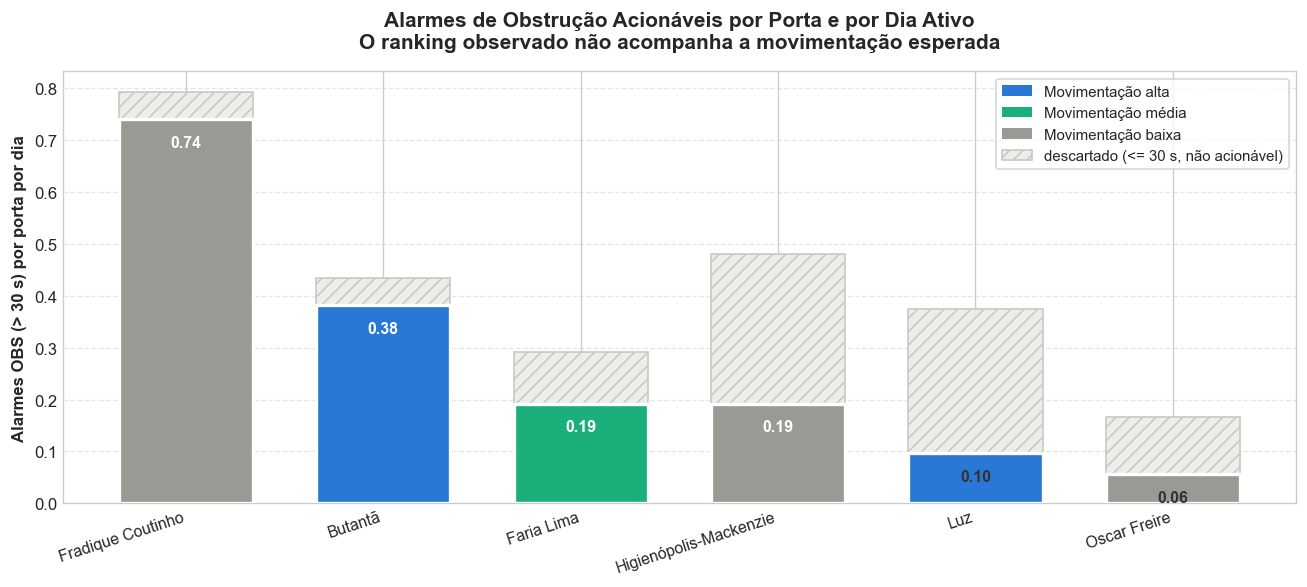

In [8]:
cores = {3: AZUL, 2: AQUA, 1: CINZA}
fig, ax = plt.subplots(figsize=(11, 5))
rotulos = [NOMES[e] for e in taxa_obs.index]

bars = ax.bar(rotulos, taxa_obs['taxa_analisado'],
              color=[cores[n] for n in taxa_obs['Nível']],
              edgecolor='white', linewidth=2, width=0.68, zorder=3)
# Empilhado por cima, apenas para dimensionar o que o recorte de 30 s retirou
ax.bar(rotulos, taxa_obs['taxa_descartado'], bottom=taxa_obs['taxa_analisado'],
       color='#ededea', edgecolor='#c9c9c4', linewidth=1, width=0.68, hatch='///', zorder=2)

for bar, v in zip(bars, taxa_obs['taxa_analisado']):
    ax.text(bar.get_x() + bar.get_width()/2, v - 0.03, f'{v:.2f}',
            ha='center', va='top', fontsize=9.5, fontweight='bold',
            color='white' if v > 0.15 else '#333333', zorder=4)

ax.legend(handles=[Patch(facecolor=cores[n], label=f'Movimentação {ROTULO[n].lower()}') for n in (3, 2, 1)]
                 + [Patch(facecolor='#ededea', edgecolor='#c9c9c4', hatch='///',
                          label='descartado (<= 30 s, não acionável)')],
          loc='upper right', frameon=True, facecolor='white', fontsize=9)
ax.set_title('Alarmes de Obstrução Acionáveis por Porta e por Dia Ativo\n'
             'O ranking observado não acompanha a movimentação esperada',
             fontsize=12.5, fontweight='bold', pad=14)
ax.set_ylabel('Alarmes OBS (> 30 s) por porta por dia', fontsize=10, fontweight='bold')
ax.tick_params(axis='x', labelsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.5)
ax.set_axisbelow(True)
plt.setp(ax.get_xticklabels(), rotation=18, ha='right')
plt.tight_layout()
plt.show()

Apartir do gráfico, é possível ver que o padrão não segue o esperado. Fradique Coutinho aparece entre as estações com maior taxa, enquanto Luz e Butantã ficam abaixo. Isso sugere que, com os dados disponíveis, a relação entre movimentação e obstruções não é clara.

## 7. Síntese
A hipótese 3 foi refutada pelos dados. Mesmo depois de tirar os eventos muito curtos, o ranking das estações não acompanha a movimentação esperada. O resultado mostrra que os dados disponíveis não permitem concluir que estações mais movimentadas geram mais alarmes de obstrução.